# 实验三：基于 SIFT、FLANN 与 RANSAC 的图像拼接

本 Notebook 按参考 PDF 的主流程实现，并加入掩膜、渐变融合、30 组参数实验及三图扩展。
**请使用 Conda 环境运行**，所有代码按顺序执行。Markdown 长报告见仓库根目录 `report.md`。

数据是 OpenCV 官方 `opencv_extra` 仓库中的 7 张实际照片，包含船坞、地图和报纸。
来源及 SHA256 见 `data/sources.json`；不是从单张照片裁切出的伪多视图。

In [1]:
from pathlib import Path
import sys, os, platform, json, csv, hashlib
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'stitching.py').exists(), '请从仓库或 notebooks 目录运行'
sys.path.insert(0, str(ROOT))
import cv2
import numpy as np
from IPython.display import display, Image, Markdown
from src.stitching import (read_image, extract_features, estimate_homography,
    stitch_pair, draw_matches, save_image, warp_layers, blend_layers, StitchingError)
cv2.setNumThreads(1)
cv2.setRNGSeed(42)
is_conda = (Path(sys.prefix) / 'conda-meta').is_dir()
assert is_conda, '本实验要求 Conda；请切换到 Python (cv-stitching) 内核'
print({'python':platform.python_version(), 'conda':is_conda,
       'environment':os.environ.get('CONDA_DEFAULT_ENV', Path(sys.prefix).name),
       'opencv':cv2.__version__, 'numpy':np.__version__})

{'python': '3.10.21', 'conda': True, 'environment': 'cvex', 'opencv': '4.11.0', 'numpy': '2.2.6'}


## 1. 检查网络照片和输入尺寸

本地已附带图片，运行时不必联网。若图片缺失，在仓库目录运行 `python scripts/download_images.py`。
先逐张检查哈希，避免图片被替换后继续套用报告中的结论。

boat1.jpg original HxW: (2592, 3888) processing HxW: (800, 1200)
boat2.jpg original HxW: (2592, 3888) processing HxW: (800, 1200)


boat3.jpg original HxW: (2592, 3888) processing HxW: (800, 1200)


budapest1.jpg original HxW: (806, 1142) processing HxW: (806, 1142)
budapest2.jpg original HxW: (806, 1142) processing HxW: (806, 1142)
newspaper1.jpg original HxW: (1125, 818) processing HxW: (1125, 818)
newspaper2.jpg original HxW: (1125, 818) processing HxW: (1125, 818)


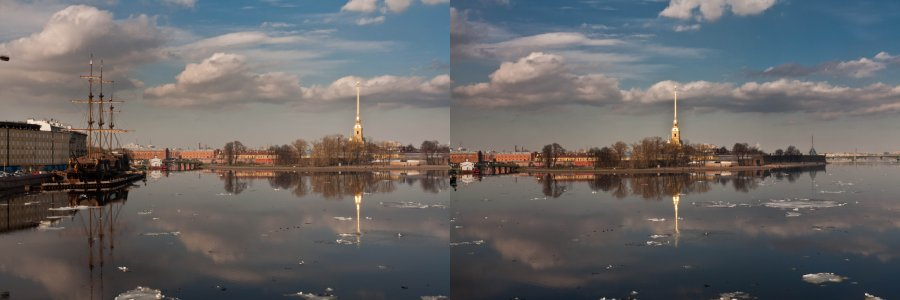

In [2]:
manifest = json.loads((ROOT/'data'/'sources.json').read_text(encoding='utf-8'))
for item in manifest['images']:
    path = ROOT/'data'/item['file']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item['sha256']
    raw = read_image(path, max_side=10000)
    small = read_image(path)
    print(item['file'], 'original HxW:',raw.shape[:2], 'processing HxW:',small.shape[:2])
a = read_image(ROOT/'data'/'boat1.jpg')
b = read_image(ROOT/'data'/'boat2.jpg')
def show_bgr(image, width=900):
    scale = min(1.0, width / image.shape[1])
    if scale < 1:
        image = cv2.resize(image,None,fx=scale,fy=scale,interpolation=cv2.INTER_AREA)
    ok, data = cv2.imencode('.jpg',image,[cv2.IMWRITE_JPEG_QUALITY,85])
    assert ok
    display(Image(data=data.tobytes(),width=width))
def show_file(path, width=1000):
    show_bgr(read_image(path,max_side=10000),width)
show_bgr(np.hstack([a,b]))

## 2. SIFT 特征点与描述符

SIFT 在灰度图上提取局部极值、方向和 128 维描述符。它对一定范围的缩放和旋转较稳定，
但不保证能处理严重模糊、无纹理天空或大视差。`nfeatures=5000` 是目标上限，极值并列时数量可能略超过上限。

A keypoints: 2495 B keypoints: 1747
descriptor shape: (2495, 128) dtype: float32


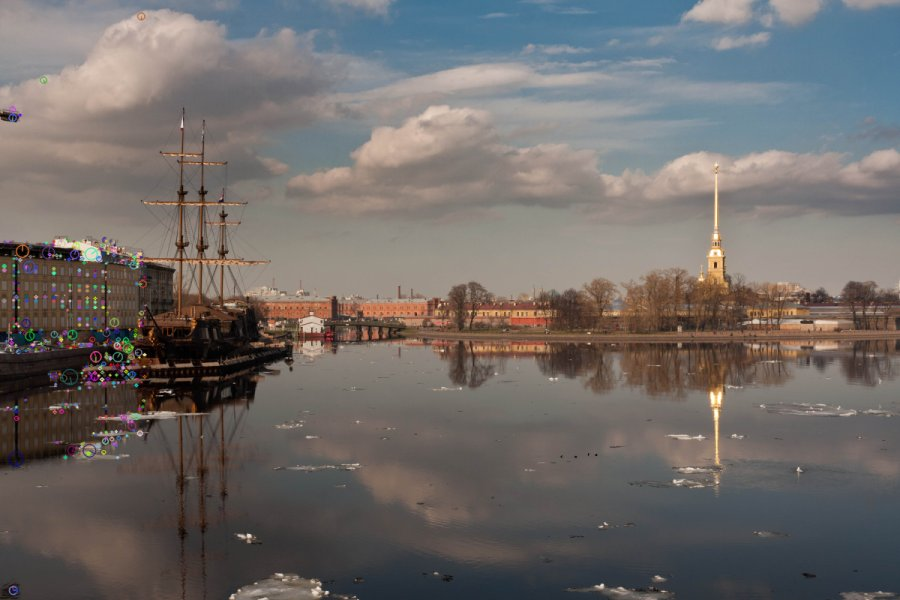

In [3]:
fa, fb = extract_features(a), extract_features(b)
print('A keypoints:',len(fa.keypoints),'B keypoints:',len(fb.keypoints))
print('descriptor shape:',fa.descriptors.shape,'dtype:',fa.descriptors.dtype)
keypoint_view = cv2.drawKeypoints(a,fa.keypoints[:500],None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
show_bgr(keypoint_view)

## 3. FLANN、Lowe 比率筛选与 RANSAC

对 A 的每个描述符寻找 B 中两个近邻，保留 $d_1<r d_2$ 的匹配，默认 $r=0.70$。
再用 RANSAC 估计几何一致的内点；默认重投影阈值为处理分辨率下 5 像素。

**坐标方向要一致：** `queryIdx` 属于 A、`trainIdx` 属于 B；
`findHomography(src=B, dst=A)` 返回 $H_{B\to A}$，后续只用这个方向变换 B。

{
  "keypoints_a": 2495,
  "keypoints_b": 1747,
  "knn_pairs": 2495,
  "good_matches": 748,
  "inliers": 670,
  "inlier_ratio": 0.8957219251336899,
  "inlier_rmse_px": 0.5057723522186279,
  "inlier_median_px": 0.1744062900543213,
  "ratio": 0.7,
  "ransac_threshold_px": 5.0
}
H (B -> A):
 [[ 8.03421424e-01 -5.48367266e-03  3.77937035e+02]
 [-6.28899510e-02  9.30143639e-01  2.04938605e+01]
 [-1.65709322e-04 -8.26113292e-07  1.00000000e+00]]


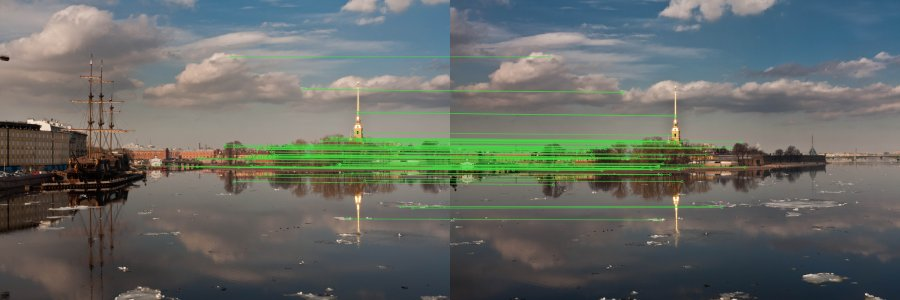

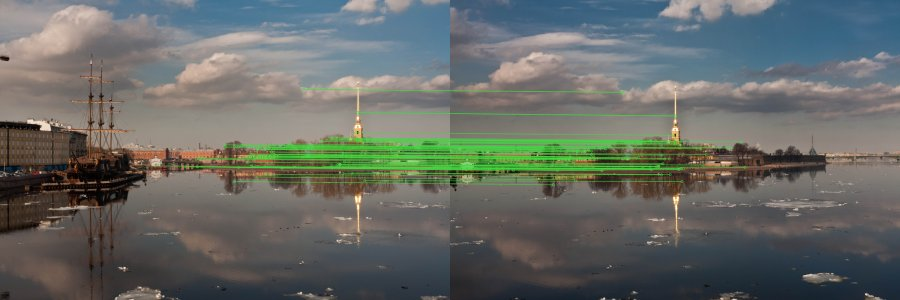

In [4]:
fit = estimate_homography(a,b,features=(fa,fb))
print(json.dumps(fit['metrics'],indent=2))
print('H (B -> A):\n',fit['H'])
show_bgr(draw_matches(a,b,fit,inliers_only=False))
show_bgr(draw_matches(a,b,fit,inliers_only=True))

## 4. 联合画布和独立有效掩膜

将 B 的四角映射到 A，再与 A 的四角求包围盒。平移矩阵 $T$ 将负坐标搬进画布，最终变换为 $TH$。
边界采用 `floor(min)` 和 `ceil(max)`，避免负坐标转换时截断。

图像内容中的黑色也是有效像素，因此必须单独变换全白掩膜，不能用 `pixel > 0` 判断有效区域。

Canvas HxW: (930, 1676)
Translation:
 [[ 1.  0.  0.]
 [ 0.  1. 69.]
 [ 0.  0.  1.]]


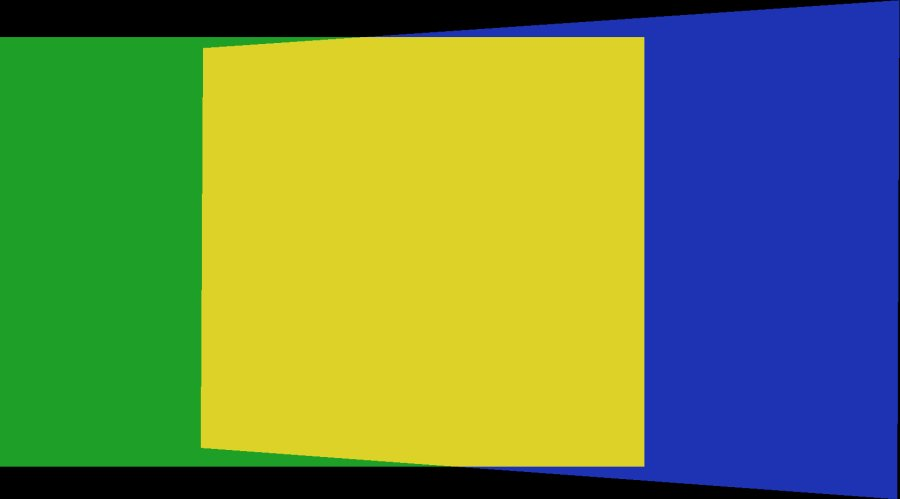

In [5]:
layers,masks,T = warp_layers([a,b],[np.eye(3),fit['H']])
print('Canvas HxW:',layers[0].shape[:2])
print('Translation:\n',T)
mask_view = np.zeros_like(layers[0])
mask_view[masks[0]]=(40,160,30)
mask_view[masks[1]]=(180,50,30)
mask_view[masks[0]&masks[1]]=(40,210,220)
show_bgr(mask_view)

## 5. 参考基线与距离渐变融合

基线先绘制 B，再用 A 直接覆盖；渐变方案按每张图像到自身掩膜边缘的距离加权：

$$I(x,y)=\frac{w_A I_A+w_B I_B}{w_A+w_B},\quad w_i=(D(M_i)+\epsilon)M_i.$$

这能减轻亮度接缝，但不能校正曝光，也不能消除几何错位和运动鬼影。

Direct overwrite:


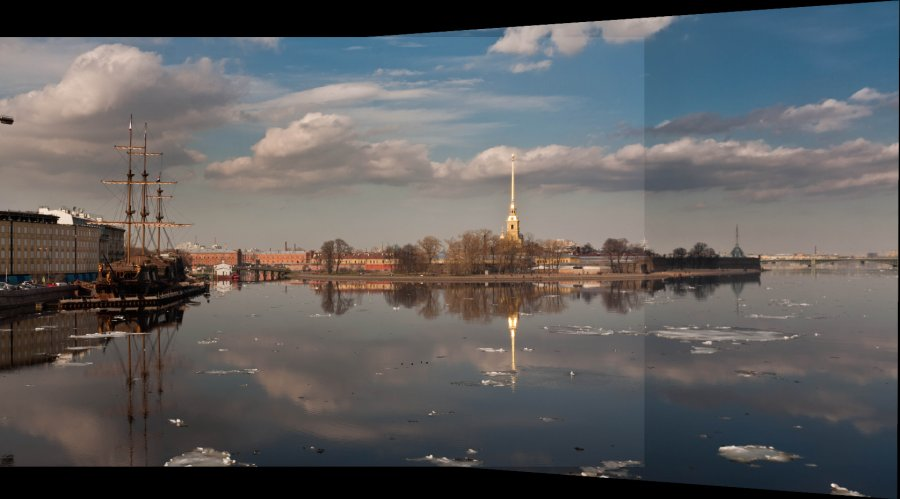

Feather:


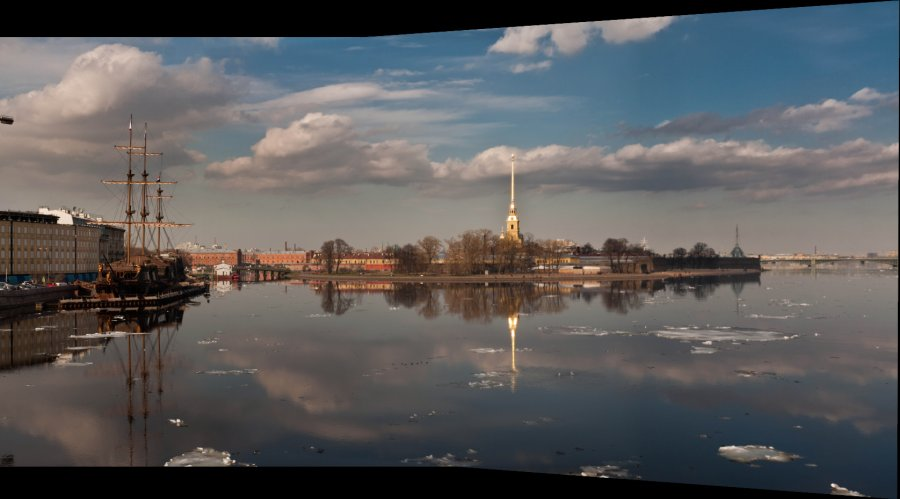

In [6]:
overwrite = blend_layers(layers,masks,'overwrite')
feather = blend_layers(layers,masks,'feather')
print('Direct overwrite:')
show_bgr(overwrite)
print('Feather:')
show_bgr(feather)

## 6. 运行完整实验

下面重新处理三组照片，保存匹配图、单应矩阵、两种融合结果、参数 CSV、亮度对照和三图拼接。
这一步会覆盖 `results/` 中的同名实验结果。计时不包括文件读取和保存。

In [7]:
from src.experiments import run_experiments
summary,sweep,triple = run_experiments(ROOT)
def md_table(rows,keys):
    header='| '+' | '.join(keys)+' |'
    separator='| '+' | '.join(['---']*len(keys))+' |'
    lines=[header,separator]
    for row in rows:
        values=[f'{row[k]:.4f}' if isinstance(row[k],float) else str(row[k]) for k in keys]
        lines.append('| '+' | '.join(values)+' |')
    return '\n'.join(lines)
display(Markdown(md_table(summary,['scene','good_matches','inliers','inlier_ratio','inlier_rmse_px','overlap_mae'])))

boat {"keypoints_a": 2495, "keypoints_b": 1747, "knn_pairs": 2495, "good_matches": 748, "inliers": 670, "inlier_ratio": 0.8957219251336899, "inlier_rmse_px": 0.5057723522186279, "inlier_median_px": 0.1744062900543213, "ratio": 0.7, "ransac_threshold_px": 5.0, "canvas_width": 1676, "canvas_height": 930, "overlap_pixels": 647958, "overlap_mae": 16.31585997857886, "elapsed_seconds": 0.6868743000086397}


budapest {"keypoints_a": 5000, "keypoints_b": 5000, "knn_pairs": 5000, "good_matches": 626, "inliers": 599, "inlier_ratio": 0.9568690095846646, "inlier_rmse_px": 1.4863359928131104, "inlier_median_px": 1.145096778869629, "ratio": 0.7, "ransac_threshold_px": 5.0, "canvas_width": 1778, "canvas_height": 816, "overlap_pixels": 407825, "overlap_mae": 14.430714154355423, "elapsed_seconds": 0.8970502000302076}


newspaper {"keypoints_a": 5001, "keypoints_b": 5000, "knn_pairs": 5001, "good_matches": 1270, "inliers": 1142, "inlier_ratio": 0.8992125984251969, "inlier_rmse_px": 0.37023985385894775, "inlier_median_px": 0.1911524534225464, "ratio": 0.7, "ransac_threshold_px": 5.0, "canvas_width": 1263, "canvas_height": 1127, "overlap_pixels": 421039, "overlap_mae": 7.792524366309693, "elapsed_seconds": 0.8503617999376729}


| scene | good_matches | inliers | inlier_ratio | inlier_rmse_px | overlap_mae |
| --- | --- | --- | --- | --- | --- |
| boat | 748 | 670 | 0.8957 | 0.5058 | 16.3159 |
| budapest | 626 | 599 | 0.9569 | 1.4863 | 14.4307 |
| newspaper | 1270 | 1142 | 0.8992 | 0.3702 | 7.7925 |

## 7. 地图和报纸场景

`budapest` 是地图纸张照片，`newspaper` 是报纸照片。平面纹理有利于单应模型，
重复道路和文字也会产生局部歧义；地图折痕及纸面不平可能造成局部残差。

budapest


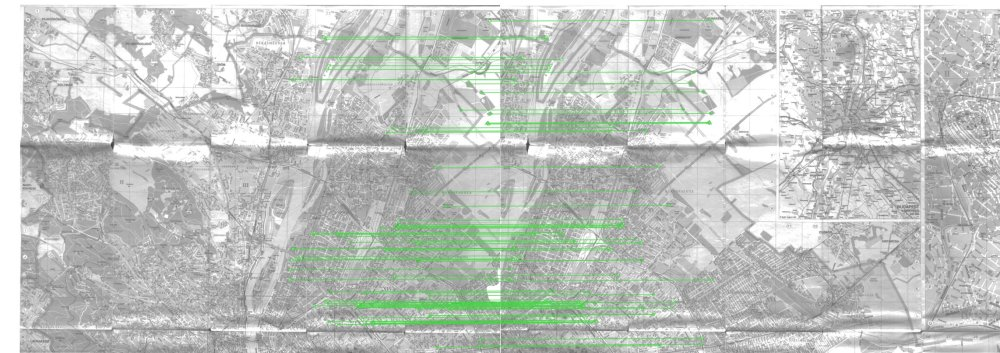

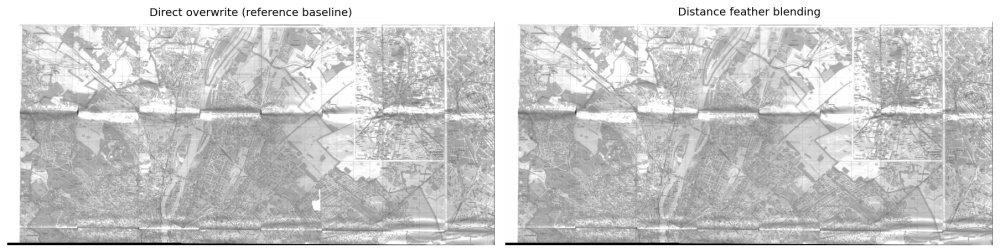

newspaper


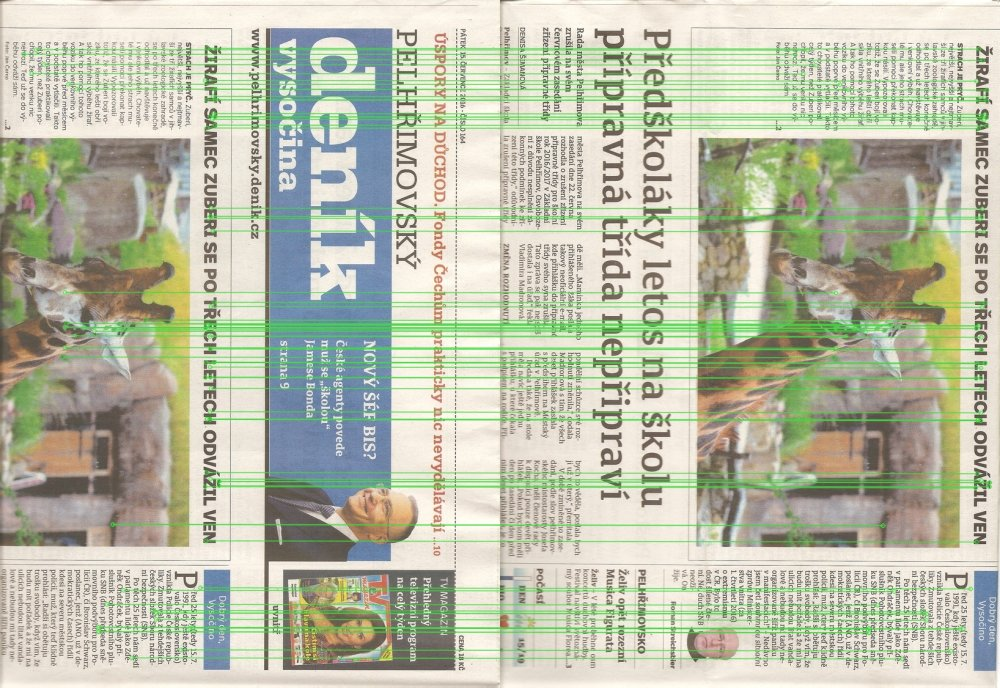

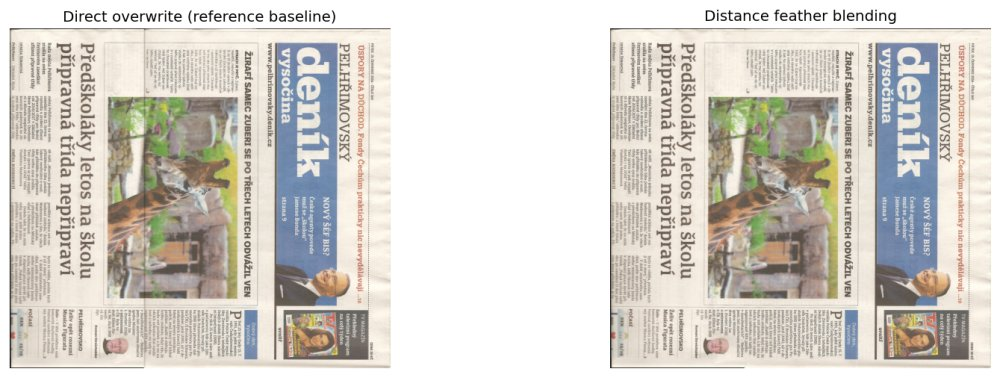

In [8]:
for name in ('budapest','newspaper'):
    print(name)
    show_file(ROOT/'results'/f'{name}_matches.jpg',width=1000)
    show_file(ROOT/'results'/f'{name}_comparison.png',width=1000)

## 8. 参数敏感性：5 个比率 × 2 个 RANSAC 阈值 × 3 个场景

参数扫描复用同一场景的特征，只重新进行匹配和几何估计。
内点率衡量匹配集在当前阈值下的一致性，不能直接当成无偏的拼接正确率。
更严格的 RANSAC 会删除较大残差的点，因此其内点 RMSE 降低不自动意味着整体图像更好。

| scene | ratio | ransac_threshold_px | good_matches | inliers | inlier_ratio | inlier_rmse_px |
| --- | --- | --- | --- | --- | --- | --- |
| boat | 0.5500 | 2.0000 | 669 | 623 | 0.9312 | 0.3571 |
| boat | 0.5500 | 5.0000 | 669 | 625 | 0.9342 | 0.4724 |
| boat | 0.6500 | 2.0000 | 722 | 658 | 0.9114 | 0.3733 |
| boat | 0.6500 | 5.0000 | 722 | 653 | 0.9044 | 0.9123 |
| boat | 0.7000 | 2.0000 | 748 | 635 | 0.8489 | 0.3399 |
| boat | 0.7000 | 5.0000 | 748 | 670 | 0.8957 | 0.5058 |
| boat | 0.7500 | 2.0000 | 786 | 671 | 0.8537 | 0.3599 |
| boat | 0.7500 | 5.0000 | 786 | 698 | 0.8880 | 0.5561 |
| boat | 0.8500 | 2.0000 | 972 | 581 | 0.5977 | 0.3107 |
| boat | 0.8500 | 5.0000 | 972 | 702 | 0.7222 | 1.1691 |
| budapest | 0.5500 | 2.0000 | 532 | 378 | 0.7105 | 0.9954 |
| budapest | 0.5500 | 5.0000 | 532 | 492 | 0.9248 | 1.4648 |
| budapest | 0.6500 | 2.0000 | 596 | 344 | 0.5772 | 0.8517 |
| budapest | 0.6500 | 5.0000 | 596 | 529 | 0.8876 | 1.3553 |
| budapest | 0.7000 | 2.0000 | 626 | 422 | 0.6741 | 0.9953 |
| budapest | 0.7000 | 5.0000 | 626 | 599 | 0.9569 | 1.4863 |
| budapest | 0.7500 | 2.0000 | 651 | 397 | 0.6098 | 1.0577 |
| budapest | 0.7500 | 5.0000 | 651 | 493 | 0.7573 | 1.3753 |
| budapest | 0.8500 | 2.0000 | 870 | 414 | 0.4759 | 1.0025 |
| budapest | 0.8500 | 5.0000 | 870 | 614 | 0.7057 | 1.5176 |
| newspaper | 0.5500 | 2.0000 | 1040 | 1004 | 0.9654 | 0.3238 |
| newspaper | 0.5500 | 5.0000 | 1040 | 1004 | 0.9654 | 0.3238 |
| newspaper | 0.6500 | 2.0000 | 1186 | 1104 | 0.9309 | 0.3401 |
| newspaper | 0.6500 | 5.0000 | 1186 | 1105 | 0.9317 | 0.3543 |
| newspaper | 0.7000 | 2.0000 | 1270 | 1137 | 0.8953 | 0.3363 |
| newspaper | 0.7000 | 5.0000 | 1270 | 1142 | 0.8992 | 0.3702 |
| newspaper | 0.7500 | 2.0000 | 1383 | 1164 | 0.8416 | 0.3529 |
| newspaper | 0.7500 | 5.0000 | 1383 | 1177 | 0.8510 | 0.3745 |
| newspaper | 0.8500 | 2.0000 | 1797 | 1230 | 0.6845 | 0.3520 |
| newspaper | 0.8500 | 5.0000 | 1797 | 1240 | 0.6900 | 0.3968 |

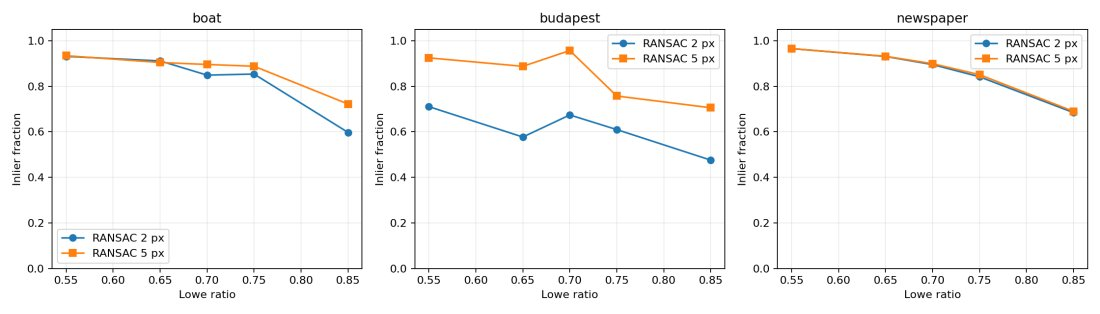

In [9]:
display(Markdown(md_table(sweep,['scene','ratio','ransac_threshold_px','good_matches','inliers','inlier_ratio','inlier_rmse_px'])))
show_file(ROOT/'results'/'parameter_sweep.png',width=1100)

## 9. 受控亮度实验

固定基础 H，将 B 亮度乘以 0.65，隔离几何和曝光因素。可以观察渐变是否把突变变成平滑过渡，
同时检查剩余的整体亮度不一致。这里没有实施增益补偿，不能将平滑过渡描述为曝光已恢复。

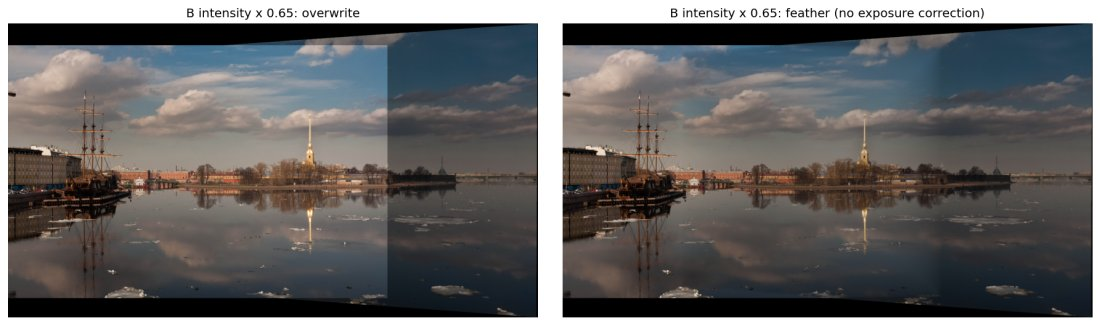

In [10]:
show_file(ROOT/'results'/'brightness_comparison.png',width=1100)

## 10. 三图扩展

用 `boat2.jpg` 作参考，分别估计 $H_{1\to2}$ 和 $H_{3\to2}$，一次性变换三张原图后融合。
这比反复对已拼图再提特征更容易解释，但没有进行全局束调整，仍可能有边缘拉伸和累计残差。

Reference: boat2.jpg Canvas WxH: 2277 968
boat1_to_boat2 {'keypoints_a': 1747, 'keypoints_b': 2495, 'knn_pairs': 1747, 'good_matches': 754, 'inliers': 659, 'inlier_ratio': 0.8740053050397878, 'inlier_rmse_px': 0.5515010952949524, 'inlier_median_px': 0.19383713603019714, 'ratio': 0.7, 'ransac_threshold_px': 5.0}
boat3_to_boat2 {'keypoints_a': 1747, 'keypoints_b': 1641, 'knn_pairs': 1747, 'good_matches': 547, 'inliers': 432, 'inlier_ratio': 0.7897623400365631, 'inlier_rmse_px': 0.5667828321456909, 'inlier_median_px': 0.19326823949813843, 'ratio': 0.7, 'ransac_threshold_px': 5.0}


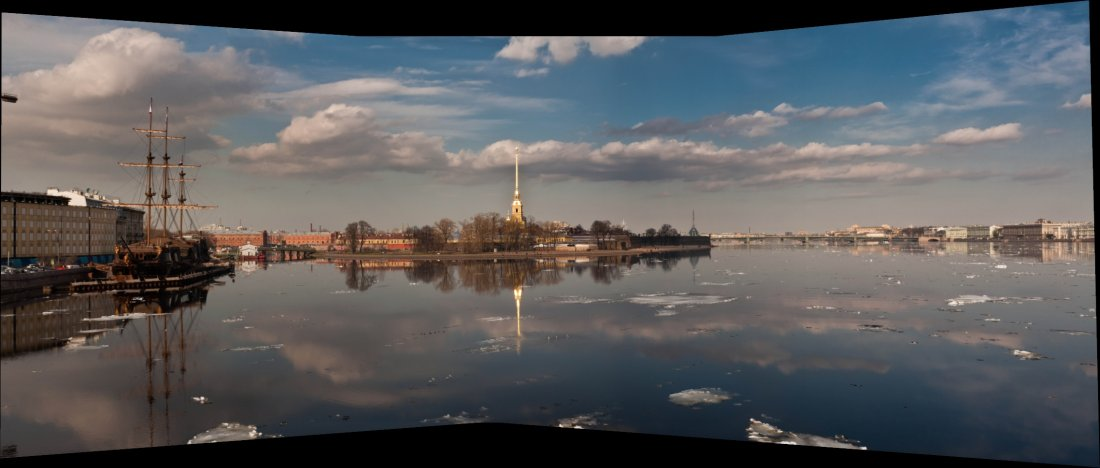

In [11]:
print('Reference:',triple['reference'],'Canvas WxH:',triple['width'],triple['height'])
for direction in ('boat1_to_boat2','boat3_to_boat2'):
    print(direction,triple[direction])
show_file(ROOT/'results'/'boat_three_images.jpg',width=1100)

## 11. 失败输入与行为测试

验证已知平移能否恢复正确的 B→A 方向、有效黑色像素是否参与融合、无纹理图和危险画布是否被拒绝。
这些测试检验可观察行为，不将函数内部实现复制成断言。

In [12]:
import unittest
suite=unittest.defaultTestLoader.discover(str(ROOT/'tests'))
test_result=unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful()

test_black_pixels_are_valid (test_stitching.StitchingTests) ... 

ok


test_known_translation (test_stitching.StitchingTests) ... 

ok


test_textureless_is_rejected (test_stitching.StitchingTests) ... 

ok


test_unbounded_canvas_is_rejected (test_stitching.StitchingTests) ... 

ok


----------------------------------------------------------------------
Ran 4 tests in 0.305s

OK


## 12. 结论与进一步思考

实测支持：三组输入都能获得足够的几何内点；船坞曝光接缝经距离融合后更平缓，地图和报纸可完成平面配准。
报告进一步讨论单应模型假设、阈值权衡、指标偏差、重影来源和改进方向。

**解读限制：** 内点 RMSE 是拟合内点上的误差，没有独立的真实全景作为测试集；重叠 MAE 是融合前两图的像素差，
同时受曝光、插值、运动和配准影响。不能据此声称获得了通用最优参数或无缝、无鬼影的全景。

In [13]:
environment=json.loads((ROOT/'results'/'environment.json').read_text(encoding='utf-8'))
assert environment['conda_runtime'] is True
print('Verified runtime:')
print(json.dumps(environment,indent=2))
print('All experiment outputs saved under results/.')

Verified runtime:
{
  "python": "3.10.21",
  "platform": "Windows-10-10.0.26200-SP0",
  "opencv": "4.11.0",
  "numpy": "2.2.6",
  "matplotlib": "3.10.3",
  "max_side": 1200,
  "seed": 42,
  "opencv_threads": 1,
  "conda_environment": "cvex",
  "conda_runtime": true,
  "note": "Timing is one run, including feature extraction, warping and two blending modes; excludes IO."
}
All experiment outputs saved under results/.
